# Delivery analysis

Olist delivers late on 6.79% of orders. This notebook asks why, and the answer turned out to be different from the one I expected when I started.

The investigation runs in the order it actually happened. I had a hypothesis about where the bottleneck was and tested it. The data supported only part of it, and following up the part it did not support led somewhere more useful. The early tests are kept in place rather than edited out, because the way the first answer failed is what made the rest of the analysis possible.

## Scope

Delivered orders purchased between 1 January 2017 and 31 August 2018: 96,203 orders.

The dataset contains 267 delivered orders before 2017, but 265 of them fall in a single month and November 2016 is entirely absent, so the 2016 series is not continuous enough to carry monthly rates. The last order in the dataset was purchased on 29 August 2018, so the upper bound states the scope rather than removing anything.

Orders that reached a carrier but never arrived are not in this population, because they have no delivery date to measure. They are counted separately in section 1, since they are the worst outcome a customer can have and a late rate computed on delivered orders cannot see them.

In [1]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

con = duckdb.connect("../olist.duckdb")

WINDOW = "purchase_date BETWEEN DATE '2017-01-01' AND DATE '2018-08-31'"

con.sql(f"""
    CREATE OR REPLACE VIEW model.v_delivery AS
    SELECT
        o.*,
        r.seller_state,
        r.customer_state,
        r.same_state,
        r.same_region,
        r.customer_region
    FROM model.fct_orders o
    LEFT JOIN model.dim_route r USING (route_key)
    WHERE {WINDOW}
""")

def q(sql):
    return con.sql(sql).df()

def show(sql, n=25):
    con.sql(sql).show(max_rows=n)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 9,
})

print(f"orders in scope: {con.execute('SELECT COUNT(*) FROM model.v_delivery').fetchall()[0][0]:,}")

orders in scope: 96,203


---

## 1. How late is late

Before asking why orders are late, it is worth knowing what lateness looks like on this platform.

In [2]:
show("""
    SELECT
        COUNT(*)                                    AS orders,
        ROUND(100 * AVG(is_late::INT), 2)           AS late_pct,
        ROUND(AVG(delivery_days), 1)                AS avg_delivery_days,
        ROUND(AVG(promised_days), 1)                AS avg_promised_days,
        ROUND(MEDIAN(days_vs_promise), 1)           AS median_days_vs_promise,
        ROUND(AVG(review_score), 2)                 AS avg_review
    FROM model.v_delivery
""")

┌────────┬──────────┬───────────────────┬───────────────────┬────────────────────────┬────────────┐
│ orders │ late_pct │ avg_delivery_days │ avg_promised_days │ median_days_vs_promise │ avg_review │
│ int64  │  double  │      double       │      double       │         double         │   double   │
├────────┼──────────┼───────────────────┼───────────────────┼────────────────────────┼────────────┤
│  96203 │     6.79 │              12.5 │              24.3 │                  -12.0 │       4.16 │
└────────┴──────────┴───────────────────┴───────────────────┴────────────────────────┴────────────┘



Two numbers stand out and they pull in opposite directions.

The late rate is 6.79%, which is not a crisis. But the average order is promised in 24.3 days and arrives in 12.5 - the median order lands **twelve days before its deadline**. Olist is not meeting a tight promise with difficulty; it is meeting a very loose promise comfortably, and still missing it one time in fifteen.

That reframes the question. The interesting variable may not be delivery speed at all. It may be the promise.

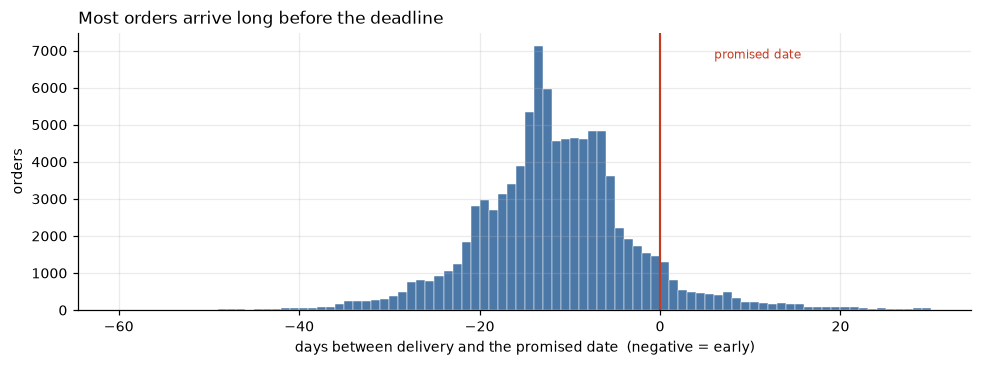

In [3]:
d = q("""
    SELECT days_vs_promise
    FROM model.v_delivery
    WHERE days_vs_promise BETWEEN -60 AND 30
""")

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(d["days_vs_promise"], bins=90, color="#4C78A8", edgecolor="white", linewidth=0.3)
ax.axvline(0, color="#C23B22", linewidth=1.4)
ax.annotate("promised date", xy=(0, ax.get_ylim()[1] * 0.92), xytext=(6, ax.get_ylim()[1] * 0.92),
            color="#C23B22", fontsize=8, va="center")
ax.set_xlabel("days between delivery and the promised date  (negative = early)")
ax.set_ylabel("orders")
ax.set_title("Most orders arrive long before the deadline", loc="left", fontsize=11)
plt.tight_layout()
plt.show()

The distribution sits almost entirely to the left of the deadline, with a long early tail and a thin late one.

### Orders that never arrived

The late rate is computed on delivered orders, so it cannot count parcels that reached a carrier and never registered a delivery.

In [4]:
show("""
    SELECT status, COUNT(*) AS orders
    FROM clean.orders
    WHERE CAST(purchase_ts AS DATE) BETWEEN DATE '2017-01-01' AND DATE '2018-08-31'
      AND carrier_ts IS NOT NULL
      AND NOT is_delivered
    GROUP BY 1 ORDER BY 2 DESC
""")

show("""
    WITH o AS (
        SELECT * FROM clean.orders
        WHERE CAST(purchase_ts AS DATE) BETWEEN DATE '2017-01-01' AND DATE '2018-08-31'
    )
    SELECT
        COUNT(*) FILTER (WHERE is_delivered)                                AS delivered,
        COUNT(*) FILTER (WHERE is_delivered AND is_late)                    AS delivered_late,
        COUNT(*) FILTER (WHERE carrier_ts IS NOT NULL AND NOT is_delivered) AS never_delivered,
        ROUND(100.0 * COUNT(*) FILTER (WHERE is_delivered AND is_late)
              / COUNT(*) FILTER (WHERE is_delivered), 2)                    AS late_rate_pct,
        ROUND(100.0 * (COUNT(*) FILTER (WHERE is_delivered AND is_late)
                     + COUNT(*) FILTER (WHERE carrier_ts IS NOT NULL AND NOT is_delivered))
              / (COUNT(*) FILTER (WHERE is_delivered)
               + COUNT(*) FILTER (WHERE carrier_ts IS NOT NULL AND NOT is_delivered)), 2)
                                                                            AS failure_rate_pct
    FROM o
""")

┌───────────┬────────┐
│  status   │ orders │
│  varchar  │ int64  │
├───────────┼────────┤
│ shipped   │   1097 │
│ canceled  │     70 │
│ delivered │      7 │
└───────────┴────────┘

┌───────────┬────────────────┬─────────────────┬───────────────┬──────────────────┐
│ delivered │ delivered_late │ never_delivered │ late_rate_pct │ failure_rate_pct │
│   int64   │     int64      │      int64      │    double     │      double      │
├───────────┼────────────────┼─────────────────┼───────────────┼──────────────────┤
│     96203 │           6531 │            1174 │          6.79 │             7.91 │
└───────────┴────────────────┴─────────────────┴───────────────┴──────────────────┘



1,174 orders were handed to a carrier and never delivered: 1,097 still marked as shipped, 70 cancelled after pickup, and 7 marked delivered but with no delivery date. Counting them as failures moves the rate from **6.79% to 7.91%**.

Everything below uses delivered orders, because delivery time can only be measured on parcels that arrived. The 1.1-point gap is worth keeping in mind whenever a late rate is quoted: it is a measure of how often arrivals were late, not of how often customers were let down. How these orders spread across routes is examined in the network analysis.

---

## 2. Late over time

If lateness were a logistics problem it should track operational conditions. The monthly series tests that, with the promise plotted alongside it.

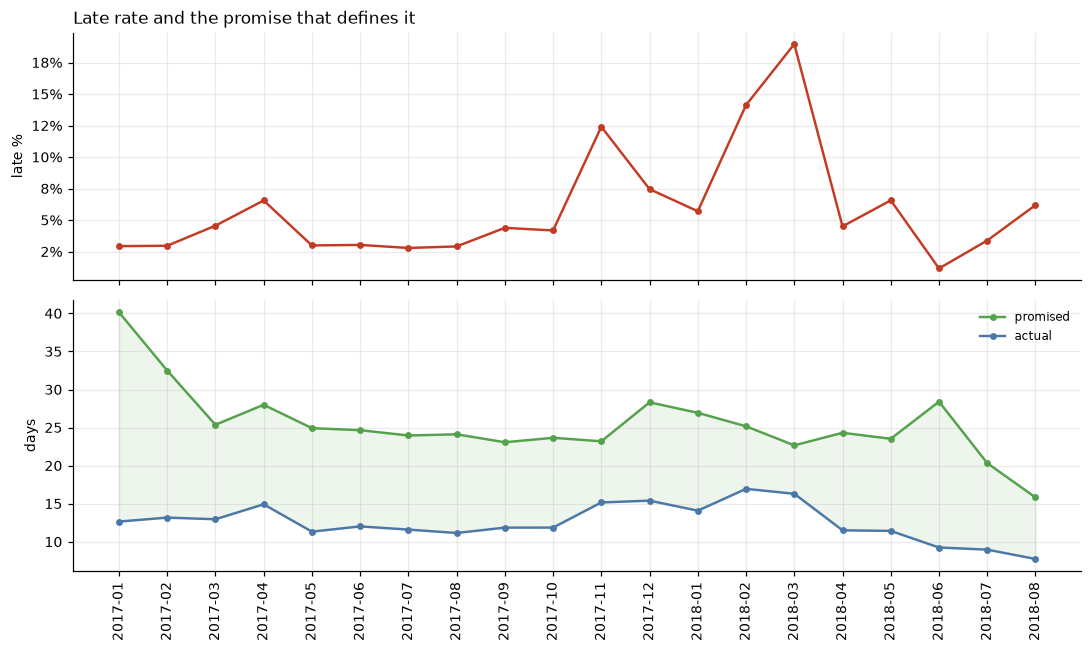

In [5]:
m = q("""
    SELECT
        strftime(purchase_date, '%Y-%m')            AS ym,
        COUNT(*)                                    AS orders,
        100 * AVG(is_late::INT)                     AS late_pct,
        AVG(delivery_days)                          AS avg_delivery,
        AVG(promised_days)                          AS avg_promised
    FROM model.v_delivery
    GROUP BY 1 ORDER BY 1
""")

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                             gridspec_kw={"height_ratios": [1, 1.1]})

a1.plot(m["ym"], m["late_pct"], color="#C23B22", marker="o", markersize=3.5, linewidth=1.6)
a1.set_ylabel("late %")
a1.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
a1.set_title("Late rate and the promise that defines it", loc="left", fontsize=11)

a2.plot(m["ym"], m["avg_promised"], color="#54A24B", marker="o", markersize=3.5,
        linewidth=1.6, label="promised")
a2.plot(m["ym"], m["avg_delivery"], color="#4C78A8", marker="o", markersize=3.5,
        linewidth=1.6, label="actual")
a2.fill_between(m["ym"], m["avg_delivery"], m["avg_promised"], color="#54A24B", alpha=0.10)
a2.set_ylabel("days")
a2.legend(frameon=False, loc="upper right", fontsize=8)
a2.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

The shaded gap between the two lines is the padding in the promise, and it is wide in almost every month. The late rate spikes do not line up with the actual delivery line - they line up with the gap narrowing.

November and December 2017 make the point.

In [6]:
show("""
    SELECT
        strftime(purchase_date, '%Y-%m')        AS ym,
        COUNT(*)                                AS orders,
        ROUND(AVG(promised_days), 1)            AS promised_days,
        ROUND(AVG(delivery_days), 1)            AS actual_days,
        ROUND(MEDIAN(transit_days), 2)          AS median_transit,
        ROUND(100 * AVG(is_late::INT), 2)       AS late_pct
    FROM model.v_delivery
    WHERE strftime(purchase_date, '%Y-%m') IN ('2017-10','2017-11','2017-12','2018-01')
    GROUP BY 1 ORDER BY 1
""")

┌─────────┬────────┬───────────────┬─────────────┬────────────────┬──────────┐
│   ym    │ orders │ promised_days │ actual_days │ median_transit │ late_pct │
│ varchar │ int64  │    double     │   double    │     double     │  double  │
├─────────┼────────┼───────────────┼─────────────┼────────────────┼──────────┤
│ 2017-10 │   4478 │          23.7 │        11.9 │           7.05 │     4.18 │
│ 2017-11 │   7288 │          23.2 │        15.2 │           8.76 │     12.4 │
│ 2017-12 │   5513 │          28.3 │        15.4 │           9.09 │     7.46 │
│ 2018-01 │   7069 │          26.9 │        14.1 │           8.04 │      5.7 │
└─────────┴────────┴───────────────┴─────────────┴────────────────┴──────────┘



November 2017 is Black Friday. Volume rises about 60% against October, the average order stretches from 11.9 days to 15.2, and the late rate triples to 12.4% - against a promise that barely moved, 23.7 days down to 23.2.

In December the promise is extended by five days, to 28.3. The late rate falls to 7.46%, a drop of two fifths, although the average December order took slightly *longer* than the November one, 15.4 days against 15.2, and median transit was worse at 9.09 days against 8.76.

This is not evidence that anyone manipulated the metric. Extending the promise into the Christmas peak after a congested November is a reasonable forecast, and a later notebook shows that a purely statistical promise rule does worse than Olist's own judgement in exactly these post-holiday months. The point is narrower and more important: **the late rate moves with the promise**, so it cannot be read as a measure of operational performance on its own. Every later result has to be read with the promise in view.

December is suggestive rather than conclusive, because the promise and the season changed together. A cleaner test needs a shock whose timing is known from outside the data.

---

## 3. A natural experiment: the 2018 truckers' strike

On 21 May 2018 Brazilian truck drivers began a national strike against diesel prices. Highways were blockaded across the country for about ten days, and by 31 May the roads were reported back to normal.

That gives a dated, external shock to road freight, which is exactly what is needed to see how the promise responds and what the late rate does as a result.

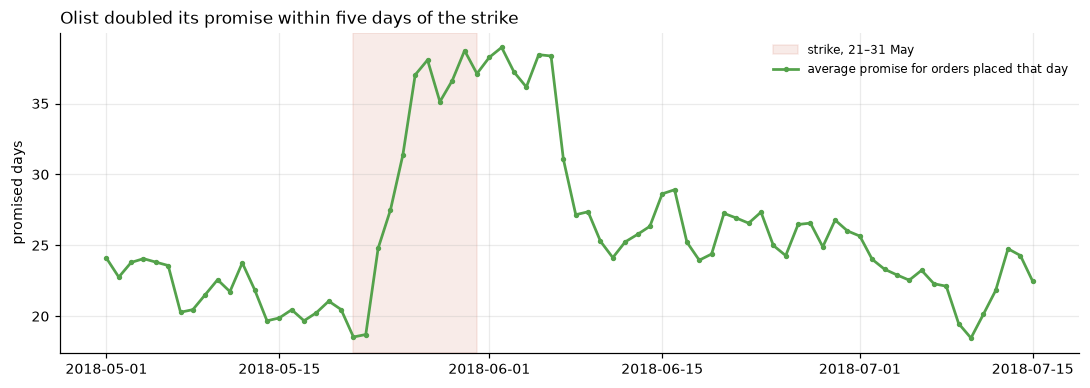

In [7]:
daily = q("""
    SELECT purchase_date, COUNT(*) AS orders, AVG(promised_days) AS promise
    FROM model.v_delivery
    WHERE purchase_date BETWEEN DATE '2018-05-01' AND DATE '2018-07-15'
    GROUP BY 1 ORDER BY 1
""")

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.axvspan(pd.Timestamp("2018-05-21"), pd.Timestamp("2018-05-31"), color="#C23B22", alpha=0.10,
           label="strike, 21–31 May")
ax.plot(daily["purchase_date"], daily["promise"], color="#54A24B", linewidth=1.8, marker="o",
        markersize=2.5, label="average promise for orders placed that day")
ax.set_ylabel("promised days")
ax.set_title("Olist doubled its promise within five days of the strike", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

In [8]:
show("""
    SELECT
        CAST(date_trunc('week', purchase_date) AS DATE)         AS purchase_week,
        COUNT(*)                                                AS orders,
        ROUND(AVG(promised_days), 1)                            AS promised_days,
        ROUND(AVG(delivery_days), 1)                            AS actual_days,
        ROUND(AVG(promised_days) - AVG(delivery_days), 1)       AS slack_days,
        ROUND(100 * AVG(is_late::INT), 1)                       AS late_pct
    FROM model.v_delivery
    WHERE purchase_date BETWEEN DATE '2018-04-30' AND DATE '2018-07-08'
    GROUP BY 1 ORDER BY 1
""")

┌───────────────┬────────┬───────────────┬─────────────┬────────────┬──────────┐
│ purchase_week │ orders │ promised_days │ actual_days │ slack_days │ late_pct │
│     date      │ int64  │    double     │   double    │   double   │  double  │
├───────────────┼────────┼───────────────┼─────────────┼────────────┼──────────┤
│ 2018-04-30    │   1734 │          23.6 │        10.7 │       12.9 │      3.7 │
│ 2018-05-07    │   1943 │          21.6 │        10.6 │       10.9 │      6.4 │
│ 2018-05-14    │   1805 │          20.1 │        12.2 │        7.9 │     12.1 │
│ 2018-05-21    │    941 │          26.0 │        12.4 │       13.5 │      4.0 │
│ 2018-05-28    │   1075 │          37.4 │        11.5 │       25.9 │      0.4 │
│ 2018-06-04    │   1421 │          32.3 │        10.2 │       22.1 │      1.3 │
│ 2018-06-11    │   1497 │          26.1 │         9.1 │       17.0 │      1.7 │
│ 2018-06-18    │   1442 │          25.8 │         8.5 │       17.3 │      1.0 │
│ 2018-06-25    │   1378 │  

The response is visible day by day. Orders placed on 21 and 22 May were still promised about 18.5 days. From 23 May the promise rises every day - 24.8, 27.5, 31.4, 37.0 - and by 26 May it has **doubled**, where it stays into June.

The strike ended after ten days and deliveries recovered quickly. Orders placed in the week of 28 May were promised 37.4 days and arrived in 11.5. Their late rate was **0.4%**. Slack, normally about twelve days, stayed near seventeen until July.

There is also a casualty week. Orders placed between 14 and 20 May carried an ordinary 20-day promise into a national shutdown that nobody had announced yet, and 12.1% of them were late.

This explains the anomaly that June 2018 otherwise presents: a 1.2% late rate, less than half that of any other month in the dataset. Nothing improved operationally. The promise had been set for a crisis that was already over. As with December, the adjustment was a sensible response to a real risk. What it shows is the size of the effect: doubling the promise took the late rate close to zero without any change in how parcels moved.

---

## 4. Where orders arrive late

Lateness is not evenly spread. Splitting it by destination separates two different problems that a national average hides.

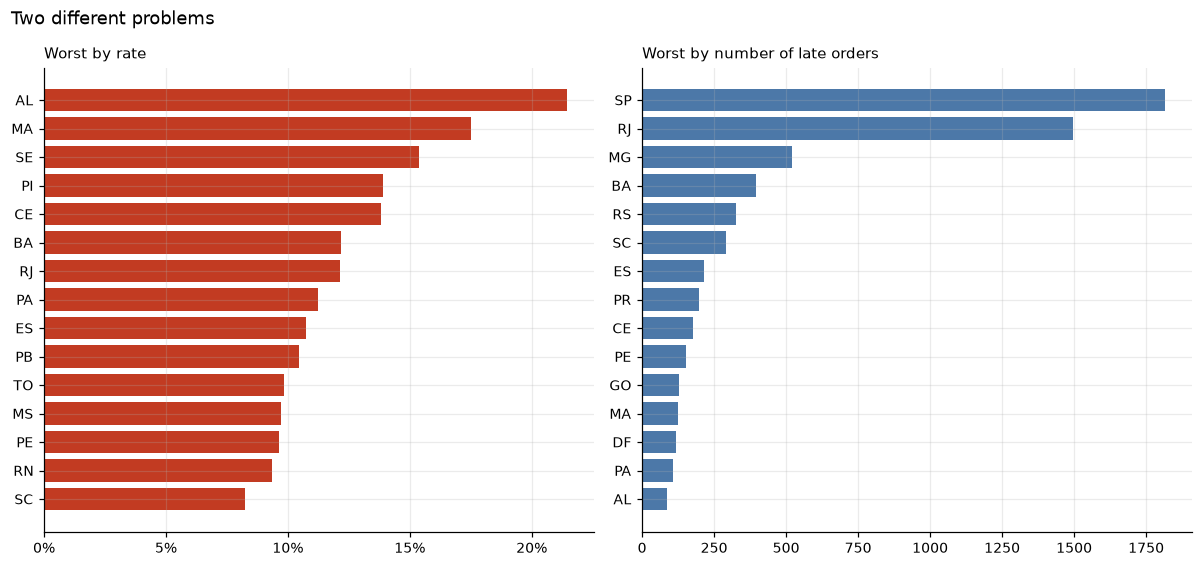

In [9]:
s = q("""
    SELECT
        customer_state,
        COUNT(*)                                        AS orders,
        100 * AVG(is_late::INT)                         AS late_pct,
        SUM(is_late::INT)                               AS late_orders,
        AVG(delivery_days)                              AS avg_delivery
    FROM model.v_delivery
    WHERE customer_state IS NOT NULL
    GROUP BY 1 HAVING COUNT(*) >= 200
    ORDER BY late_pct DESC
""")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 5.2))

top = s.head(15).iloc[::-1]
a1.barh(top["customer_state"], top["late_pct"], color="#C23B22")
a1.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
a1.set_title("Worst by rate", loc="left", fontsize=10)

vol = s.sort_values("late_orders", ascending=False).head(15).iloc[::-1]
a2.barh(vol["customer_state"], vol["late_orders"], color="#4C78A8")
a2.set_title("Worst by number of late orders", loc="left", fontsize=10)

fig.suptitle("Two different problems", x=0.012, ha="left", fontsize=11.5)
plt.tight_layout()
plt.show()

The two charts barely overlap, and the difference matters for what anyone would do about it.

The rate chart is dominated by small northern and north-eastern states. Roraima, Amapá and Alagoas have severe delivery problems but a few hundred orders between them. Fixing them improves a ratio and almost nothing else.

The volume chart is dominated by São Paulo, Rio de Janeiro and Minas Gerais, where the rate is unremarkable but the base is enormous. Most of Olist's late orders are in states that look fine on a percentage.

A recommendation built on the first chart and a recommendation built on the second are different recommendations.

---

## 5. A hypothesis about São Paulo

São Paulo is not simply the largest state on this platform. It is structurally central to it.

In [10]:
show("""
    SELECT 'sellers based in SP'       AS measure,
           ROUND(100 * AVG((state = 'SP')::INT), 1) AS pct
    FROM model.dim_seller
    UNION ALL
    SELECT 'orders shipped from SP',
           ROUND(100 * AVG((seller_state = 'SP')::INT), 1)
    FROM model.v_delivery
    UNION ALL
    SELECT 'orders delivered to SP',
           ROUND(100 * AVG((customer_state = 'SP')::INT), 1)
    FROM model.v_delivery
""")

┌────────────────────────┬────────┐
│        measure         │  pct   │
│        varchar         │ double │
├────────────────────────┼────────┤
│ sellers based in SP    │   58.7 │
│ orders shipped from SP │   70.4 │
│ orders delivered to SP │   42.0 │
└────────────────────────┴────────┘



58.7% of sellers are in São Paulo, and they ship **70.4%** of all orders - so SP sellers are not only numerous, they are individually busier than sellers elsewhere. Meanwhile only 42% of customers are there. The platform is a single origin hub serving a continent.

That structure suggests a hypothesis:

> **If São Paulo sellers are the capacity constraint, then in months when SP demand peaks they should fall behind on dispatch, and that delay should show up as lateness for customers everywhere - including customers nowhere near São Paulo.**

If it holds, the recommendation writes itself: recruit sellers outside SP so that demand spikes have somewhere else to go.

Testing it requires separating the part of delivery a seller controls from the part a carrier controls.

---

## 6. Splitting the clock

Every delivered order carries four timestamps, which divide the journey into three stages that belong to different parties.

| Stage | From → to | Who owns it |
| --- | --- | --- |
| Approval | purchase → payment approved | the payment method |
| Dispatch | approval → handed to carrier | the seller |
| Transit | carrier → customer | the carrier network |

Measured separately, they are nothing alike.

In [11]:
show("""
    SELECT
        ROUND(MEDIAN(approval_days), 2)     AS median_approval,
        ROUND(MEDIAN(dispatch_days), 2)     AS median_dispatch,
        ROUND(MEDIAN(transit_days), 2)      AS median_transit,
        ROUND(STDDEV(approval_days), 2)     AS sd_approval,
        ROUND(STDDEV(dispatch_days), 2)     AS sd_dispatch,
        ROUND(STDDEV(transit_days), 2)      AS sd_transit,
        ROUND(CORR(approval_days, days_vs_promise), 3) AS approval_vs_outcome,
        ROUND(CORR(dispatch_days, days_vs_promise), 3) AS dispatch_vs_outcome,
        ROUND(CORR(transit_days,  days_vs_promise), 3) AS transit_vs_outcome
    FROM model.v_delivery
""")

┌─────────────────┬─────────────────┬────────────────┬─────────────┬─────────────┬────────────┬─────────────────────┬─────────────────────┬────────────────────┐
│ median_approval │ median_dispatch │ median_transit │ sd_approval │ sd_dispatch │ sd_transit │ approval_vs_outcome │ dispatch_vs_outcome │ transit_vs_outcome │
│     double      │     double      │     double     │   double    │   double    │   double   │       double        │       double        │       double       │
├─────────────────┼─────────────────┼────────────────┼─────────────┼─────────────┼────────────┼─────────────────────┼─────────────────────┼────────────────────┤
│            0.01 │            1.81 │            7.1 │        0.86 │        3.45 │       8.77 │               0.042 │               0.207 │              0.585 │
└─────────────────┴─────────────────┴────────────────┴─────────────┴─────────────┴────────────┴─────────────────────┴─────────────────────┴────────────────────┘



Approval is effectively instant at the median - a quarter of an hour - and correlates with the final outcome at 0.04. It is noise.

Dispatch takes a median 1.8 days and correlates at 0.21.

Transit takes a median 7.1 days, has by far the widest spread, and correlates with whether an order is late at **0.59**.

So transit is where the variance lives. That does not yet refute the hypothesis - a seller who dispatches late pushes the parcel into the carrier network late, and the delay would surface in a stage the seller does not own. The hypothesis has to be tested on its own terms, against dispatch time directly.

---

## 7. Testing the hypothesis

If SP sellers buckle under load, their dispatch time should rise in their busiest months.

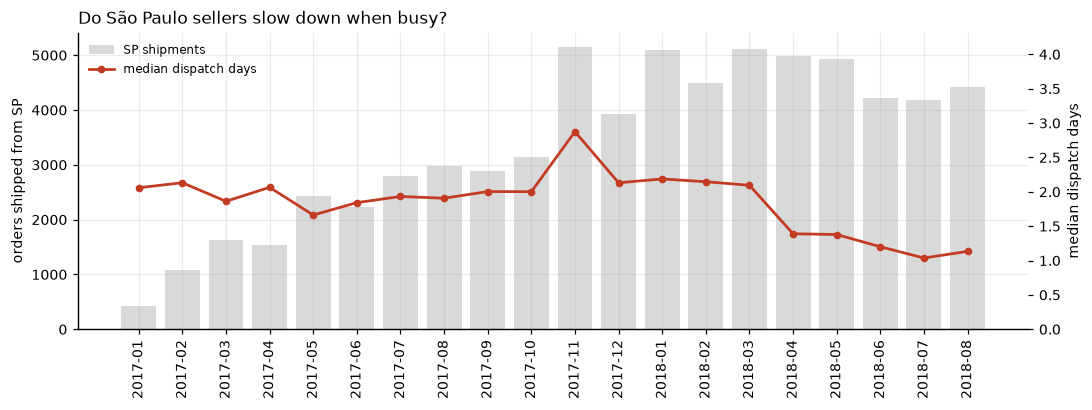

In [12]:
mm = q("""
    SELECT
        strftime(purchase_date, '%Y-%m')                                     AS ym,
        COUNT(*) FILTER (WHERE seller_state = 'SP')                          AS sp_shipments,
        MEDIAN(dispatch_days) FILTER (WHERE seller_state = 'SP')             AS sp_dispatch,
        MEDIAN(transit_days)  FILTER (WHERE seller_state = 'SP')             AS sp_transit,
        100 * AVG(is_late::INT) FILTER (WHERE customer_state <> 'SP')        AS late_outside_sp
    FROM model.v_delivery
    GROUP BY 1 ORDER BY 1
""")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(mm["ym"], mm["sp_shipments"], color="#D9D9D9", label="SP shipments")
ax.set_ylabel("orders shipped from SP")
ax.tick_params(axis="x", rotation=90)

ax2 = ax.twinx()
ax2.plot(mm["ym"], mm["sp_dispatch"], color="#C23B22", marker="o", markersize=4,
         linewidth=1.8, label="median dispatch days")
ax2.set_ylabel("median dispatch days")
ax2.set_ylim(0, mm["sp_dispatch"].max() * 1.5)
ax2.grid(False)

ax.set_title("Do São Paulo sellers slow down when busy?", loc="left", fontsize=11)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

In [13]:
rng = np.random.default_rng(7)

def corr_with_ci(df, a, b, reps=5000):
    x, y = df[a].to_numpy(), df[b].to_numpy()
    n = len(x)
    boots = [np.corrcoef(x[i], y[i])[0, 1] for i in (rng.integers(0, n, n) for _ in range(reps))]
    lo, hi = np.nanpercentile(boots, [2.5, 97.5])
    return round(np.corrcoef(x, y)[0, 1], 2), round(lo, 2), round(hi, 2)

pairs = [("sp_shipments", "sp_dispatch"), ("sp_shipments", "late_outside_sp"),
         ("sp_dispatch", "late_outside_sp"), ("sp_transit", "late_outside_sp")]

levels = pd.DataFrame(
    [(f"{a} ~ {b}", *corr_with_ci(mm, a, b)) for a, b in pairs],
    columns=["relationship", "r", "ci_low", "ci_high"])
levels

,relationship,r,ci_low,ci_high
0,sp_shipments ~ sp_dispatch,-0.15,-0.64,0.28
1,sp_shipments ~ late_outside_sp,0.53,0.30,0.72
2,sp_dispatch ~ late_outside_sp,0.47,0.18,0.73
3,sp_transit ~ late_outside_sp,0.78,0.52,0.90


At first sight the hypothesis fails. Across the 20 months, SP volume and SP dispatch time correlate at **−0.15**: in busier months, dispatch was if anything slightly faster. The chart shows the long-run pattern behind that number. Dispatch time falls from about 2.1 days in early 2017 to 1.1 by mid-2018, while monthly volume rises roughly tenfold.

Two things stop this from being a rejection.

The first is sample size. Twenty months are twenty data points, and the bootstrap interval for −0.15 runs from −0.64 to +0.28. It cannot be distinguished from zero.

The second is that both series carry a two-year trend, and a correlation between levels mixes that trend with the month-to-month shocks the hypothesis is actually about. The same problem produces a misleading result in the other direction: volume and lateness outside São Paulo correlate at 0.53, which taken alone would look like a confirmation. Both series simply grew over two years.

Removing the trend means correlating month-on-month changes instead of levels.

In [14]:
changes = mm[["sp_shipments", "sp_dispatch", "sp_transit", "late_outside_sp"]].diff().dropna()

pd.DataFrame(
    [(f"{a} ~ {b}", *corr_with_ci(changes, a, b)) for a, b in pairs],
    columns=["relationship (month-on-month change)", "r", "ci_low", "ci_high"])

,relationship (month-on-month change),r,ci_low,ci_high
0,sp_shipments ~ sp_dispatch,0.59,-0.18,0.86
1,sp_shipments ~ late_outside_sp,0.33,-0.31,0.76
2,sp_dispatch ~ late_outside_sp,0.69,0.18,0.88
3,sp_transit ~ late_outside_sp,0.76,0.24,0.93


On changes, the sign flips. Months in which SP volume jumped tend to be months in which SP dispatch slowed, at **+0.59** - not significant with 19 observations, but no longer evidence against the hypothesis. Transit keeps the strongest relationship with lateness under both treatments.

Monthly totals cannot really settle a question about whether individual sellers buckle under their own load. Order-level data can, by comparing each seller with themselves.

In [15]:
seller_load = """
    WITH sp AS (
        SELECT order_id, main_seller_id AS sid,
               date_trunc('week', purchase_date) AS wk, dispatch_days
        FROM model.v_delivery
        WHERE seller_state = 'SP' AND dispatch_days IS NOT NULL),
    seller_week AS (SELECT sid, wk, COUNT(*) AS wk_orders FROM sp GROUP BY 1, 2),
    seller_norm AS (
        SELECT sid, AVG(wk_orders) AS typical_week, COUNT(*) AS active_weeks, SUM(wk_orders) AS total
        FROM seller_week GROUP BY 1),
    platform_week AS (SELECT wk, MEDIAN(dispatch_days) AS wk_median FROM sp GROUP BY 1)
    SELECT
        sp.sid,
        sp.dispatch_days,
        sw.wk_orders / sn.typical_week          AS load_ratio,
        sp.dispatch_days - pw.wk_median         AS excess_vs_same_week
    FROM sp
    JOIN seller_week   sw USING (sid, wk)
    JOIN seller_norm   sn USING (sid)
    JOIN platform_week pw USING (wk)
    WHERE sn.total >= 50 AND sn.active_weeks >= 10
"""

load = q(seller_load)
load["load_band"] = pd.cut(load["load_ratio"], [0, 0.75, 1.5, 2.5, np.inf],
                           labels=["quiet (<0.75x)", "normal (0.75-1.5x)", "busy (1.5-2.5x)", "surge (2.5x+)"],
                           right=False)

load.groupby("load_band", observed=True).agg(
    orders=("dispatch_days", "size"),
    sellers=("sid", "nunique"),
    median_dispatch=("dispatch_days", "median"),
    excess_vs_same_week=("excess_vs_same_week", "mean"),
).round(2)

,orders,sellers,median_dispatch,excess_vs_same_week
load_band,,,,
quiet (<0.75x),10346,275,1.72,0.89
normal (0.75-1.5x),21778,275,1.82,0.85
busy (1.5-2.5x),15617,275,1.88,0.81
surge (2.5x+),5741,204,2.29,1.13


Each SP seller with a meaningful track record - at least 50 orders over at least 10 active weeks - is compared with their own typical week. Each order's dispatch time is measured against the median dispatch of all SP orders that same week, which removes anything that hit the whole platform at once, such as a public holiday.

Up to 2.5 times their normal weekly volume, sellers show no sign of strain at all: dispatch relative to the platform is flat across quiet, normal and busy weeks. Beyond that, median dispatch rises from 1.82 days to 2.29.

That jump comes from several thousand orders, which makes it look solid. But orders from the same seller in the same busy week share a warehouse, staff and a backlog, so they are not independent observations. Treating them as independent overstates the evidence. Resampling whole sellers rather than individual orders gives the honest uncertainty.

In [16]:
grp = load.assign(
    surge=load["load_ratio"] >= 2.5,
    normal=(load["load_ratio"] >= 0.75) & (load["load_ratio"] < 1.5))

per_seller = grp.groupby("sid").apply(lambda g: pd.Series({
    "surge_sum": g.loc[g.surge, "excess_vs_same_week"].sum(),  "surge_n": g.surge.sum(),
    "normal_sum": g.loc[g.normal, "excess_vs_same_week"].sum(), "normal_n": g.normal.sum(),
}), include_groups=False).sort_index()

arr = per_seller.to_numpy()
point = arr[:, 0].sum() / arr[:, 1].sum() - arr[:, 2].sum() / arr[:, 3].sum()

rng = np.random.default_rng(11)
boots = []
for _ in range(5000):
    s = arr[rng.integers(0, len(arr), len(arr))].sum(axis=0)
    boots.append(s[0] / s[1] - s[2] / s[3])
lo, hi = np.percentile(boots, [2.5, 97.5])

print(f"surge minus normal, extra dispatch days: {point:+.2f}")
print(f"seller-clustered 95% interval:          [{lo:+.2f}, {hi:+.2f}]")

surge minus normal, extra dispatch days: +0.28
seller-clustered 95% interval:          [-0.12, +0.69]


The surge effect is about a quarter of a day, with an interval that crosses zero. It cannot be distinguished from no effect.

The verdict on the hypothesis therefore has three parts:

- **In normal operation**, São Paulo sellers absorb up to two and a half times their usual volume with no sign of strain.
- **Under extreme surges** there is a suggestive slowdown that this data cannot confirm.
- **Over the long run**, sellers scaled with demand. Capacity is not a structural constraint.

Seller capacity is not what makes most orders late. The original recommendation, to recruit sellers outside São Paulo, may still be right, but it needs a different reason.

---

## 8. What moves instead

Transit time correlates with lateness outside São Paulo at **0.78**, with a bootstrap interval of roughly 0.5 to 0.9, and the relationship survives on month-on-month changes as well.

Four consecutive months of 2018 show it directly, because they hold volume almost constant while transit swings.

In [17]:
show("""
    SELECT
        strftime(purchase_date, '%Y-%m')                                     AS ym,
        COUNT(*) FILTER (WHERE seller_state = 'SP')                          AS sp_shipments,
        ROUND(MEDIAN(dispatch_days) FILTER (WHERE seller_state = 'SP'), 2)   AS sp_dispatch,
        ROUND(MEDIAN(transit_days)  FILTER (WHERE seller_state = 'SP'), 2)   AS sp_transit,
        ROUND(100 * AVG(is_late::INT) FILTER (WHERE customer_state <> 'SP'), 2) AS late_outside_sp
    FROM model.v_delivery
    WHERE strftime(purchase_date, '%Y-%m') BETWEEN '2018-01' AND '2018-04'
    GROUP BY 1 ORDER BY 1
""")

┌─────────┬──────────────┬─────────────┬────────────┬─────────────────┐
│   ym    │ sp_shipments │ sp_dispatch │ sp_transit │ late_outside_sp │
│ varchar │    int64     │   double    │   double   │     double      │
├─────────┼──────────────┼─────────────┼────────────┼─────────────────┤
│ 2018-01 │         5102 │        2.19 │       7.54 │            7.35 │
│ 2018-02 │         4498 │        2.15 │      11.19 │           18.68 │
│ 2018-03 │         5120 │         2.1 │       9.87 │           25.99 │
│ 2018-04 │         4988 │        1.39 │       6.39 │            6.72 │
└─────────┴──────────────┴─────────────┴────────────┴─────────────────┘



February shipped *fewer* orders than January and its late rate was two and a half times higher. March matched January's volume almost exactly and was worse again. April matched March's volume and the late rate fell back to normal.

Volume explains none of this. From January to March, while the late rate outside São Paulo nearly quadrupled, SP dispatch time stayed flat at about 2.1 days. Transit rose from 7.5 days to 11.2 and fell back to 6.4 in April, and the late rate followed it.

The main constraint is the carrier network, not the sellers.

---

## 9. If transit is the problem, distance should be too

A carrier-network constraint implies that how far a parcel travels should matter. The model carries a straight-line distance between seller and customer zip centroids, which makes this directly testable.

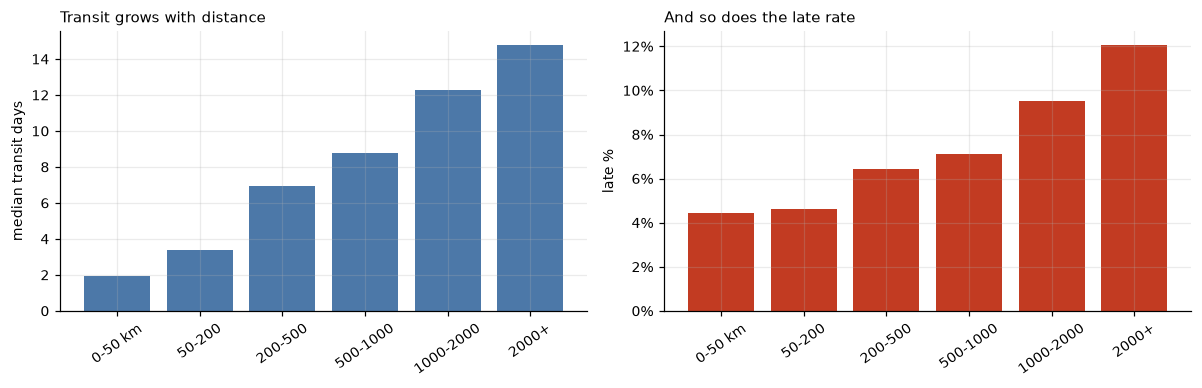

┌─────────────────────┐
│ distance_vs_transit │
│       double        │
├─────────────────────┤
│                0.42 │
└─────────────────────┘



In [18]:
dist = q("""
    SELECT
        CASE
            WHEN distance_km IS NULL   THEN 'unknown'
            WHEN distance_km <   50    THEN '0-50 km'
            WHEN distance_km <  200    THEN '50-200'
            WHEN distance_km <  500    THEN '200-500'
            WHEN distance_km < 1000    THEN '500-1000'
            WHEN distance_km < 2000    THEN '1000-2000'
            ELSE '2000+'
        END                                         AS band,
        COUNT(*)                                    AS orders,
        MEDIAN(transit_days)                        AS median_transit,
        100 * AVG(is_late::INT)                     AS late_pct,
        AVG(review_score)                           AS avg_review,
        MIN(COALESCE(distance_km, 99999))           AS sort_key
    FROM model.v_delivery
    GROUP BY 1 ORDER BY sort_key
""")

plot = dist[dist["band"] != "unknown"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))

a1.bar(plot["band"], plot["median_transit"], color="#4C78A8")
a1.set_ylabel("median transit days")
a1.tick_params(axis="x", rotation=35)
a1.set_title("Transit grows with distance", loc="left", fontsize=10)

a2.bar(plot["band"], plot["late_pct"], color="#C23B22")
a2.set_ylabel("late %")
a2.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
a2.tick_params(axis="x", rotation=35)
a2.set_title("And so does the late rate", loc="left", fontsize=10)

plt.tight_layout()
plt.show()

show("SELECT ROUND(CORR(distance_km, transit_days), 3) AS distance_vs_transit FROM model.v_delivery")

Transit climbs from 2.0 days under 50 km to 14.8 days beyond 2,000 km, and the late rate roughly triples across the same span, from 4.4% to 12.1%. Average review score slides from 4.28 to 3.97.

The correlation at order level is 0.42 - clear but not overwhelming, which is what should be expected. Two parcels travelling the same distance can take very different routes through the network.

---

## 10. Local sellers against São Paulo sellers

If distance drives transit, then a customer buying from a seller in their own state should receive the parcel sooner than the same customer buying from São Paulo. This compares the two directly, for customers outside São Paulo.

In [19]:
show("""
    SELECT
        customer_state,
        COUNT(*)                                                                AS orders,
        ROUND(MEDIAN(transit_days) FILTER (WHERE same_state), 2)                AS transit_local_seller,
        ROUND(MEDIAN(transit_days) FILTER (WHERE seller_state = 'SP'), 2)       AS transit_sp_seller,
        COUNT(*) FILTER (WHERE same_state)                                      AS local_orders
    FROM model.v_delivery
    WHERE customer_state <> 'SP' AND customer_state IS NOT NULL
    GROUP BY 1
    HAVING COUNT(*) FILTER (WHERE same_state) >= 50
    ORDER BY orders DESC
""")

┌────────────────┬────────┬──────────────────────┬───────────────────┬──────────────┐
│ customer_state │ orders │ transit_local_seller │ transit_sp_seller │ local_orders │
│    varchar     │ int64  │        double        │      double       │    int64     │
├────────────────┼────────┼──────────────────────┼───────────────────┼──────────────┤
│ RJ             │  12310 │                 2.23 │              9.14 │          973 │
│ MG             │  11319 │                 4.85 │              7.35 │         1560 │
│ RS             │   5327 │                 3.02 │             10.82 │          288 │
│ PR             │   4903 │                 4.23 │              7.77 │          716 │
│ SC             │   3537 │                 4.16 │             10.29 │          269 │
│ BA             │   3253 │                 4.98 │             14.09 │           66 │
│ DF             │   2074 │                 1.19 │              8.13 │           50 │
└────────────────┴────────┴──────────────────────┴────

Every state, the same direction, and the gaps are large. Rio de Janeiro drops from 9.1 days to 2.2. Bahia drops from 14.1 to 5.0. Brasília from 8.1 to 1.2.

This is the strongest evidence so far for the original recommendation - but not for the original reason. Recruiting sellers outside São Paulo would help, not because it relieves overloaded SP warehouses, which are not overloaded in normal operation, but because it shortens the leg that actually breaks.

Before accepting it, the obvious objection has to be dealt with. Local sellers might simply be selling smaller, lighter things that move faster anyway. If so, this table measures product mix rather than geography.

---

## 11. Is it distance, or is it the parcels?

Testing that objection needs a measure of how big an order is, and there are two reasons the obvious approach is wrong.

The first is that size belongs at order grain, not product grain. An order of ten small items is not a small order - what matters is what gets loaded onto the van.

The second is that weight alone misdescribes freight. A pillow and a brick can weigh the same while one of them fills the vehicle, so carriers bill on **cubed weight**: a volumetric weight derived from the parcel's dimensions, charged whenever it exceeds the actual weight. Using grams alone would systematically understate exactly the bulky, awkward orders most likely to be slow.

So the measure here is the greater of total weight and total volumetric weight, summed across every item in the order.

In [20]:
con.sql("""
    CREATE OR REPLACE VIEW model.v_delivery_sized AS
    SELECT
        *,
        volume_cm3 / 6.0                                        AS volumetric_g,
        GREATEST(COALESCE(weight_g, 0),
                 COALESCE(volume_cm3 / 6.0, 0))                 AS billable_g,
        CASE
            WHEN weight_g IS NULL OR volume_cm3 IS NULL              THEN 'Not sure'
            WHEN GREATEST(weight_g, volume_cm3 / 6.0) <  1000        THEN 'Small'
            WHEN GREATEST(weight_g, volume_cm3 / 6.0) <  5000        THEN 'Medium'
            WHEN GREATEST(weight_g, volume_cm3 / 6.0) < 20000        THEN 'Large'
            ELSE 'Oversize'
        END                                                     AS size_band
    FROM model.v_delivery
""")

show("""
    SELECT
        ROUND(100 * AVG((volume_cm3 / 6.0 > weight_g)::INT), 1) AS pct_billed_on_volume
    FROM model.v_delivery_sized
    WHERE weight_g IS NOT NULL AND volume_cm3 IS NOT NULL
""")

┌──────────────────────┐
│ pct_billed_on_volume │
│        double        │
├──────────────────────┤
│                 67.1 │
└──────────────────────┘



**67.1% of orders are billed on volume rather than weight.** Two thirds of what Olist ships is bulkier than it is heavy, which confirms that weight alone would have been the wrong variable.

The bands below are fixed round thresholds rather than quantiles, so that each one keeps a physical meaning: Small is roughly a shoebox, Oversize is furniture. Only 22 orders out of 96,203 are missing dimensions.

In [21]:
show("""
    SELECT
        size_band,
        COUNT(*)                                    AS orders,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)  AS pct_of_orders,
        ROUND(MEDIAN(dispatch_days), 2)             AS median_dispatch,
        ROUND(MEDIAN(transit_days), 2)              AS median_transit,
        ROUND(100 * AVG(is_late::INT), 2)           AS late_pct
    FROM model.v_delivery_sized
    GROUP BY 1
    ORDER BY CASE size_band WHEN 'Small' THEN 1 WHEN 'Medium' THEN 2
                            WHEN 'Large' THEN 3 WHEN 'Oversize' THEN 4 ELSE 5 END
""")

┌───────────┬────────┬───────────────┬─────────────────┬────────────────┬──────────┐
│ size_band │ orders │ pct_of_orders │ median_dispatch │ median_transit │ late_pct │
│  varchar  │ int64  │    double     │     double      │     double     │  double  │
├───────────┼────────┼───────────────┼─────────────────┼────────────────┼──────────┤
│ Small     │  39680 │          41.2 │            1.71 │           7.02 │     6.62 │
│ Medium    │  37456 │          38.9 │            1.77 │           7.13 │     6.58 │
│ Large     │  17303 │          18.0 │            2.07 │           7.28 │     7.39 │
│ Oversize  │   1742 │           1.8 │            2.95 │           7.08 │      9.3 │
│ Not sure  │     22 │           0.0 │            1.53 │           7.04 │      0.0 │
└───────────┴────────┴───────────────┴─────────────────┴────────────────┴──────────┘



Size does something, but not what was expected.

**Transit is flat across every band** - 7.0 days for a shoebox, 7.1 for furniture. The carrier network does not care how big the parcel is.

**Dispatch is not flat.** It climbs from 1.71 days for Small to 2.95 for Oversize, and the late rate rises with it, from 6.6% to 9.3%. Bulk slows the seller, not the carrier - which makes sense, since packing and collecting a wardrobe is harder than packing a phone case.

That is a genuine finding, and it also means size cannot explain the geography result. If size affected transit, it could explain the local-seller gap. It does not touch transit at all.

The direct test confirms it.

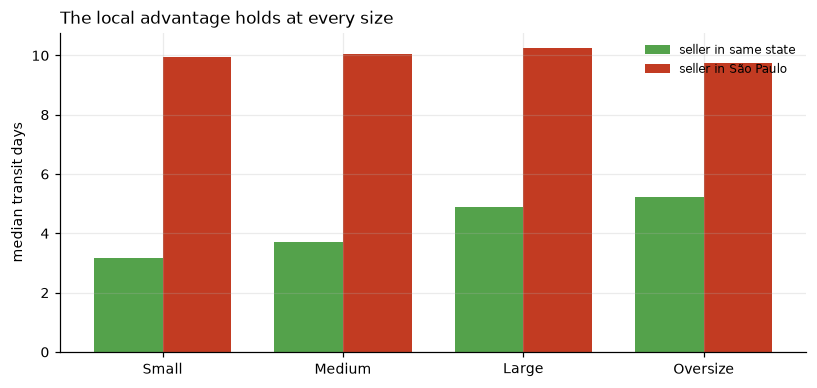

,size_band,local_seller,sp_seller,local_orders
0,Small,3.17,9.96,1540
1,Medium,3.72,10.06,1544
2,Large,4.89,10.25,867
3,Oversize,5.23,9.75,84


In [22]:
sz = q("""
    SELECT
        size_band,
        ROUND(MEDIAN(transit_days) FILTER (WHERE same_state), 2)            AS local_seller,
        ROUND(MEDIAN(transit_days) FILTER (WHERE seller_state = 'SP'), 2)   AS sp_seller,
        COUNT(*) FILTER (WHERE same_state)                                  AS local_orders
    FROM model.v_delivery_sized
    WHERE customer_state <> 'SP' AND customer_state IS NOT NULL
      AND size_band <> 'Not sure'
    GROUP BY 1
    ORDER BY CASE size_band WHEN 'Small' THEN 1 WHEN 'Medium' THEN 2
                            WHEN 'Large' THEN 3 ELSE 4 END
""")

x = range(len(sz)); w = 0.38
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.bar([i - w/2 for i in x], sz["local_seller"], w, label="seller in same state", color="#54A24B")
ax.bar([i + w/2 for i in x], sz["sp_seller"],    w, label="seller in São Paulo",  color="#C23B22")
ax.set_xticks(list(x)); ax.set_xticklabels(sz["size_band"])
ax.set_ylabel("median transit days")
ax.set_title("The local advantage holds at every size", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

sz

The gap survives intact in every band - roughly three days against ten, from Small through to Oversize. The sample sizes are now in the hundreds and thousands rather than the dozens available when the comparison was made state by state.

The product-mix objection does not hold. The local-seller advantage is about distance.

---

## 12. Do sellers make distant customers wait?

Distant customers wait longer on the road. A further question is whether they also wait longer in the seller's warehouse: whether sellers quietly deal with nearby, simpler orders first and leave long-distance parcels for later.

Comparing average dispatch times across sellers would not answer this, because different sellers serve different places. The comparison has to be made within each seller.

In [23]:
show("""
    WITH x AS (
        SELECT
            main_seller_id AS sid,
            dispatch_days,
            seller_missed_handoff,
            CASE WHEN customer_state = 'SP'  THEN '1 within SP'
                 WHEN distance_km < 1000     THEN '2 other state, under 1000 km'
                 ELSE                             '3 other state, 1000 km or more' END AS destination
        FROM model.v_delivery
        WHERE seller_state = 'SP' AND n_sellers = 1
          AND dispatch_days IS NOT NULL AND distance_km IS NOT NULL),
    eligible AS (
        SELECT sid FROM x GROUP BY 1
        HAVING COUNT(DISTINCT destination) = 3 AND COUNT(*) >= 30),
    y AS (
        SELECT x.*, dispatch_days - AVG(dispatch_days) OVER (PARTITION BY sid) AS vs_own_average
        FROM x JOIN eligible USING (sid))
    SELECT
        destination,
        COUNT(*)                                        AS orders,
        COUNT(DISTINCT sid)                             AS sellers,
        ROUND(MEDIAN(dispatch_days), 2)                 AS median_dispatch,
        ROUND(AVG(vs_own_average), 3)                   AS days_vs_own_average,
        ROUND(100 * AVG(seller_missed_handoff::INT), 1) AS missed_deadline_pct
    FROM y GROUP BY 1 ORDER BY 1
""")

┌────────────────────────────────┬────────┬─────────┬─────────────────┬─────────────────────┬─────────────────────┐
│          destination           │ orders │ sellers │ median_dispatch │ days_vs_own_average │ missed_deadline_pct │
│            varchar             │ int64  │  int64  │     double      │       double        │       double        │
├────────────────────────────────┼────────┼─────────┼─────────────────┼─────────────────────┼─────────────────────┤
│ 1 within SP                    │  25295 │     384 │             1.8 │              -0.022 │                 9.0 │
│ 2 other state, under 1000 km   │  23710 │     384 │            1.91 │               0.028 │                 8.8 │
│ 3 other state, 1000 km or more │   7687 │     384 │            1.91 │              -0.012 │                 8.3 │
└────────────────────────────────┴────────┴─────────┴─────────────────┴─────────────────────┴─────────────────────┘



Each order's dispatch time is measured against that same seller's average, for São Paulo sellers who ship both locally and far away. The differences are a few hundredths of a day, less than an hour, and the share of orders that miss the handoff deadline is the same whatever the destination. On average, nobody is being pushed to the back.

Averages could still hide a queue that is reordered case by case. That can be tested directly, because each order records when the seller could start on it (payment approval) and when it left (carrier pickup). For any two orders that reached the same seller within 24 hours of each other, the earlier one should leave first if the seller works first come, first served.

In [24]:
con.sql("""
    CREATE OR REPLACE TEMP TABLE queue_orders AS
    SELECT order_id, main_seller_id AS sid, approved_ts,
           CAST(carrier_ts AS DATE) AS pickup_day,
           (customer_state = seller_state) AS near
    FROM model.v_delivery
    WHERE n_sellers = 1
      AND approved_ts IS NOT NULL AND carrier_ts IS NOT NULL
      AND carrier_ts > approved_ts
      AND NOT timestamp_anomaly
""")

con.sql("""
    CREATE OR REPLACE TEMP TABLE queue_pairs AS
    SELECT
        a.sid,
        a.near AS earlier_near,
        b.near AS later_near,
        CASE WHEN b.pickup_day < a.pickup_day THEN 'later order left first'
             WHEN b.pickup_day > a.pickup_day THEN 'left in order'
             ELSE 'same pickup day' END AS outcome
    FROM queue_orders a
    JOIN queue_orders b
      ON a.sid = b.sid
     AND b.approved_ts >  a.approved_ts
     AND b.approved_ts <= a.approved_ts + INTERVAL 24 HOUR
""")

show("""
    SELECT outcome, COUNT(*) AS pairs,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
    FROM queue_pairs GROUP BY 1 ORDER BY 2 DESC
""")

┌────────────────────────┬───────┬────────┐
│        outcome         │ pairs │  pct   │
│        varchar         │ int64 │ double │
├────────────────────────┼───────┼────────┤
│ same pickup day        │ 65465 │   51.7 │
│ left in order          │ 47106 │   37.2 │
│ later order left first │ 13971 │   11.0 │
└────────────────────────┴───────┴────────┘



Three decisions keep the test fair. Clocks start at payment approval rather than purchase, because a seller cannot begin on an order whose payment has not cleared, and boleto payments can take a day. Only single-seller orders are used, because a multi-seller order has one pickup time that cannot be attributed to either seller. And pickups are compared by day: carriers collect in batches, so two orders leaving on the same day are a tie, not a queue decision.

About half of all pairs leave together in the same pickup. Of the rest, three quarters leave in the order they arrived. Sellers mostly work first come, first served, with some reordering - plausibly stock, packing or product type.

The question that matters is who gets moved forward when the order does change.

In [25]:
show("""
    SELECT
        CASE WHEN later_near THEN 'later order is local, earlier is distant'
             ELSE                 'later order is distant, earlier is local' END AS situation,
        COUNT(*)                                                               AS pairs,
        ROUND(100.0 * AVG((outcome = 'later order left first')::INT), 1)       AS pct_later_left_first
    FROM queue_pairs
    WHERE earlier_near <> later_near
      AND outcome <> 'same pickup day'
    GROUP BY 1 ORDER BY 1
""")

┌──────────────────────────────────────────┬───────┬──────────────────────┐
│                situation                 │ pairs │ pct_later_left_first │
│                 varchar                  │ int64 │        double        │
├──────────────────────────────────────────┼───────┼──────────────────────┤
│ later order is distant, earlier is local │ 13618 │                 23.1 │
│ later order is local, earlier is distant │ 13199 │                 22.6 │
└──────────────────────────────────────────┴───────┴──────────────────────┘



When a local order arrives after a distant one, it leaves first 22.6% of the time. When a distant order arrives after a local one, it leaves first 23.1% of the time. The direction makes no difference.

Sellers do not make distant customers wait. Whatever extra time a far-away customer spends waiting is spent on the road, which is consistent with everything above.

---

## 13. The review problem

Review scores are the obvious way to price all of this, and they contain a trap that would invert the conclusion if missed.

In [26]:
show("""
    SELECT
        is_late,
        COUNT(*)                                                                AS reviewed_orders,
        ROUND(100.0 * AVG(review_before_delivery::INT), 1)                      AS pct_reviewed_before_arrival,
        ROUND(AVG(review_score) FILTER (WHERE review_before_delivery), 2)       AS score_if_before,
        ROUND(AVG(review_score) FILTER (WHERE NOT review_before_delivery), 2)   AS score_if_after
    FROM model.v_delivery
    WHERE has_review
    GROUP BY 1 ORDER BY 1
""")

┌─────────┬─────────────────┬─────────────────────────────┬─────────────────┬────────────────┐
│ is_late │ reviewed_orders │ pct_reviewed_before_arrival │ score_if_before │ score_if_after │
│ boolean │      int64      │           double            │     double      │     double     │
├─────────┼─────────────────┼─────────────────────────────┼─────────────────┼────────────────┤
│ false   │           89182 │                         3.1 │            4.28 │           4.29 │
│ true    │            6378 │                        83.6 │            1.97 │           3.78 │
└─────────┴─────────────────┴─────────────────────────────┴─────────────────┴────────────────┘



On orders that arrived on time, 3.1% of reviews were written before the parcel did. On late orders, **83.6%** were.

The mechanism is in the survey timing: Olist sends the review request on the estimated delivery date. If the parcel is late, the customer is asked to rate an order they have not received.

Late orders reviewed before arrival average **1.97**; late orders reviewed after arrival average **3.78** - a difference of nearly two full stars attributable to survey timing rather than to anything a seller did.

That explanation is an inference from timestamps. The review text can test it directly: if customers are rating a parcel that has not arrived, they should say so.

In [27]:
con.sql("""
    CREATE OR REPLACE TEMP VIEW review_text AS
    SELECT
        v.order_id, v.is_late, v.review_before_delivery, v.review_score,
        lower(strip_accents(COALESCE(r.review_comment_title, '') || ' ' ||
                            COALESCE(r.review_comment_message, ''))) AS txt
    FROM model.v_delivery v
    JOIN raw.order_reviews r USING (order_id)
    WHERE v.has_review AND COALESCE(r.review_comment_message, '') <> ''
""")

NOT_ARRIVED = ("regexp_matches(txt, '(nao (recebi|chegou|foi entregue|entregaram)|"
               "ainda nao (recebi|chegou)|aguardando|esperando|nao recebemos|cade (o|meu))')")

show(f"""
    SELECT
        CASE WHEN is_late AND review_before_delivery THEN '1 late, reviewed before arrival'
             WHEN is_late                            THEN '2 late, reviewed after arrival'
             ELSE                                         '3 on time' END AS grp,
        COUNT(*)                                  AS reviews_with_text,
        SUM(({NOT_ARRIVED})::INT)                 AS says_not_arrived,
        ROUND(100.0 * AVG(({NOT_ARRIVED})::INT), 1) AS pct_says_not_arrived,
        ROUND(AVG(review_score), 2)               AS avg_score
    FROM review_text GROUP BY 1 ORDER BY 1
""")

show(f"""
    SELECT review_score, left(txt, 110) AS comment
    FROM review_text
    WHERE is_late AND review_before_delivery AND {NOT_ARRIVED}
    ORDER BY order_id LIMIT 6
""")

┌─────────────────────────────────┬───────────────────┬──────────────────┬──────────────────────┬───────────┐
│               grp               │ reviews_with_text │ says_not_arrived │ pct_says_not_arrived │ avg_score │
│             varchar             │       int64       │      int128      │        double        │  double   │
├─────────────────────────────────┼───────────────────┼──────────────────┼──────────────────────┼───────────┤
│ 1 late, reviewed before arrival │              3326 │             1679 │                 50.5 │      1.71 │
│ 2 late, reviewed after arrival  │               444 │               32 │                  7.2 │      3.45 │
│ 3 on time                       │             35137 │             1553 │                  4.4 │      3.97 │
└─────────────────────────────────┴───────────────────┴──────────────────┴──────────────────────┴───────────┘

┌──────────────┬───────────────────────────────────────────────────────────────────────────────────────────────────────

The pattern searches for the ordinary Portuguese ways of saying the product has not arrived - *não recebi* (I didn't receive it), *ainda não chegou* (it still hasn't arrived), *aguardando* (waiting). It only catches explicit phrasings, so every figure is a lower bound.

Among late orders reviewed before arrival, **50.5%** of written comments say outright that the product has not arrived. For late orders reviewed after arrival the figure is 7.2%, and for on-time orders 4.4%. Typical comments, translated: *"So far I haven't received the product"*, *"My product hasn't arrived... according to tracking it's stuck in Ribeirão Preto"*, and one from a customer who wrote that they could not form an opinion until the parcel arrived - and gave one star.

Most one-star reviews on late orders are not judgements of the product or the seller. They are complaints that the parcel has not come. Any seller rating built from raw review scores therefore penalises sellers for carrier delays and for Olist's survey schedule, which matters for the seller scorecard.

---

## 14. Where the damage is done

If lateness costs reviews, the next question is how much lateness it takes, and whether the damage scales.

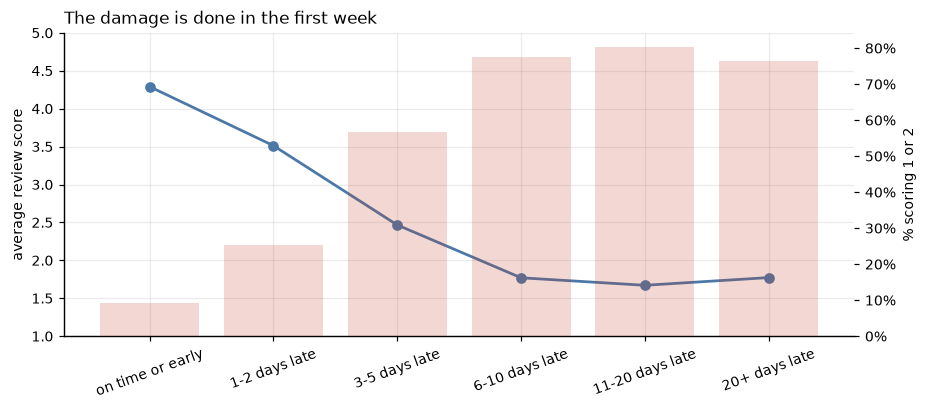

,band,orders,avg_review,pct_one_or_two_star
0,on time or early,89182,4.291157,9.247382
1,1-2 days late,1355,3.512915,25.461255
2,3-5 days late,1366,2.467057,56.734993
3,6-10 days late,1634,1.770502,77.478580
4,11-20 days late,1260,1.671429,80.238095
5,20+ days late,763,1.773263,76.539974


In [28]:
tp = q("""
    SELECT
        CASE
            WHEN days_vs_promise <=  0 THEN 'on time or early'
            WHEN days_vs_promise <=  2 THEN '1-2 days late'
            WHEN days_vs_promise <=  5 THEN '3-5 days late'
            WHEN days_vs_promise <= 10 THEN '6-10 days late'
            WHEN days_vs_promise <= 20 THEN '11-20 days late'
            ELSE '20+ days late'
        END                                             AS band,
        COUNT(*)                                        AS orders,
        AVG(review_score)                               AS avg_review,
        100.0 * AVG((review_score <= 2)::INT)           AS pct_one_or_two_star,
        MIN(days_vs_promise)                            AS sort_key
    FROM model.v_delivery
    WHERE has_review
    GROUP BY 1 ORDER BY sort_key
""")

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(tp["band"], tp["avg_review"], color="#4C78A8", marker="o", linewidth=1.8, label="average score")
ax.set_ylabel("average review score"); ax.set_ylim(1, 5)
ax.tick_params(axis="x", rotation=20)

ax2 = ax.twinx()
ax2.bar(tp["band"], tp["pct_one_or_two_star"], color="#C23B22", alpha=0.20)
ax2.set_ylabel("% scoring 1 or 2")
ax2.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax2.grid(False)

ax.set_title("The damage is done in the first week", loc="left", fontsize=11)
plt.tight_layout()
plt.show()

tp.drop(columns="sort_key")

The collapse is front-loaded and then it stops.

An order on time averages 4.29. Two days late costs most of a star, at 3.51. By three to five days late the average is 2.47 and more than half of all reviews are one or two stars. By six to ten days it has bottomed out at 1.77.

Past ten days nothing further happens. An order twenty days late scores no worse than one eight days late, because the customer has already given the lowest score available.

### Does the price of the order change the damage?

A reasonable expectation is that customers waiting for an expensive order are angrier when it is late. If so, order value would tell Olist which late customers to contact first.

In [29]:
pv = q("""
    WITH b AS (
        SELECT *,
            CASE WHEN items_value <  50 THEN '1 under R$50'
                 WHEN items_value < 100 THEN '2 R$50-100'
                 WHEN items_value < 200 THEN '3 R$100-200'
                 WHEN items_value < 500 THEN '4 R$200-500'
                 ELSE                        '5 R$500 and over' END AS value_band,
            CASE WHEN days_vs_promise <= 0 THEN 'on_time'
                 WHEN days_vs_promise <= 5 THEN 'late_1_5'
                 ELSE                           'late_6_plus' END   AS lateness
        FROM model.v_delivery WHERE has_review)
    SELECT value_band, lateness, COUNT(*) AS n,
           AVG(review_score) AS score, VAR_SAMP(review_score) AS var
    FROM b GROUP BY 1, 2
""")

w = pv.pivot(index="value_band", columns="lateness", values=["n", "score", "var"])
out = pd.DataFrame(index=w.index)
out["on_time_score"] = w[("score", "on_time")]
for lb in ["late_1_5", "late_6_plus"]:
    pen = w[("score", "on_time")] - w[("score", lb)]
    se  = np.sqrt(w[("var", "on_time")] / w[("n", "on_time")] + w[("var", lb)] / w[("n", lb)])
    out[f"stars_lost_{lb}"]   = pen
    out[f"ci_low_{lb}"]       = pen - 1.96 * se
    out[f"ci_high_{lb}"]      = pen + 1.96 * se
out.round(2)

,on_time_score,stars_lost_late_1_5,ci_low_late_1_5,ci_high_late_1_5,stars_lost_late_6_plus,ci_low_late_6_plus,ci_high_late_6_plus
value_band,,,,,,,
1 under R$50,4.34,1.31,1.19,1.42,2.58,2.49,2.66
2 R$50-100,4.30,1.34,1.23,1.46,2.51,2.43,2.59
3 R$100-200,4.28,1.28,1.16,1.40,2.59,2.51,2.66
4 R$200-500,4.20,1.33,1.15,1.51,2.49,2.37,2.60
5 R$500 and over,4.19,1.05,0.71,1.38,2.56,2.37,2.75


It does not. Being one to five days late costs about 1.3 stars whether the order cost R$30 or R$300. Six or more days late costs about 2.5 stars in every price band. The R$500-and-over band looks slightly more forgiving at one to five days, but its interval overlaps all the others.

Expensive orders score slightly lower even when they arrive on time, 4.19 against 4.34 for the cheapest, so customers are a little harder to please on expensive purchases in general. Lateness itself costs the same.

For deciding which late customers to contact, price is not useful. How late the order is going to be matters far more, because the damage is concentrated between two and six days past the promise.

---

## 15. A check on the end of the data

The dataset stops abruptly, and orders still on their way at the cutoff are absent from a delivered-only population. They would be disproportionately the slow ones, which could make the final months look better than they were - and several results above rely on mid-2018 being genuinely faster.

In [30]:
show("""
    SELECT
        strftime(CAST(purchase_ts AS DATE), '%Y-%m')                     AS purchase_month,
        COUNT(*)                                                         AS orders,
        COUNT(*) FILTER (WHERE is_delivered)                             AS delivered,
        COUNT(*) FILTER (WHERE status = 'shipped')                       AS still_with_carrier,
        ROUND(100.0 * AVG(is_delivered::INT), 1)                         AS pct_delivered
    FROM clean.orders
    WHERE CAST(purchase_ts AS DATE) BETWEEN DATE '2018-01-01' AND DATE '2018-08-31'
    GROUP BY 1 ORDER BY 1
""")

show("SELECT MAX(delivered_ts) AS last_delivery_recorded FROM clean.orders")

┌────────────────┬────────┬───────────┬────────────────────┬───────────────┐
│ purchase_month │ orders │ delivered │ still_with_carrier │ pct_delivered │
│    varchar     │ int64  │   int64   │       int64        │    double     │
├────────────────┼────────┼───────────┼────────────────────┼───────────────┤
│ 2018-01        │   7269 │      7069 │                 74 │          97.2 │
│ 2018-02        │   6728 │      6555 │                 57 │          97.4 │
│ 2018-03        │   7211 │      7003 │                133 │          97.1 │
│ 2018-04        │   6939 │      6798 │                 99 │          98.0 │
│ 2018-05        │   6873 │      6749 │                 54 │          98.2 │
│ 2018-06        │   6167 │      6096 │                 43 │          98.8 │
│ 2018-07        │   6292 │      6156 │                 60 │          97.8 │
│ 2018-08        │   6512 │      6351 │                 47 │          97.5 │
└────────────────┴────────┴───────────┴────────────────────┴───────────────┘

The delivered share is between 97% and 99% in every month through August 2018, and the number of orders still with a carrier is no higher at the end of the series than in the middle. Deliveries are recorded until 17 October 2018, so even the last August orders had about seven weeks to arrive.

Truncation at the end of the data is not driving the improvement seen in mid-2018. It is real.

---

## 16. What this analysis establishes

**The late rate moves with the promise.** The median order arrives twelve days before its deadline. In December 2017 the promise was extended by five days and the late rate fell by two fifths while deliveries got marginally slower. During the 2018 truckers' strike the promise doubled within five days and the late rate for orders placed in the following week fell to 0.4%. These look like sensible responses to real risks, not manipulation, but they show that the late rate cannot be used as a measure of operational performance on its own.

**The late rate also misses the worst outcome.** 1,174 orders reached a carrier and never arrived. Counting them, the failure rate is 7.91% rather than 6.79%.

**Seller capacity is not the main constraint.** São Paulo sellers handle 70.4% of all shipments. Compared with themselves, they absorb up to two and a half times their normal weekly volume with no sign of strain, and over two years their dispatch time fell while volume grew roughly tenfold. Extreme surges may slow them, but the evidence does not reach significance once orders from the same seller are treated as related.

**Sellers treat distant customers fairly.** Within the same seller, dispatch time and missed deadlines do not depend on destination, and when the queue is reordered, local orders move ahead no more often than distant ones.

**The carrier network is the main constraint, and distance is the mechanism.** Transit dominates both the duration and the variance of delivery and correlates with monthly lateness at 0.78. It rises from 2.0 days under 50 km to 14.8 beyond 2,000 km. Customers buying from a seller in their own state receive orders in about three days against about ten from São Paulo, at every parcel size.

**Parcel size affects the seller, not the carrier.** Dispatch rises from 1.7 days to 3.0 between the smallest and largest orders while transit stays flat at about 7.1. Two thirds of orders are billed on volume rather than weight.

**Most bad reviews on late orders are about a parcel that has not arrived.** 83.6% of reviews on late orders were written before delivery, because the survey goes out on the estimated date. Half of those comments say so explicitly. They average 1.97 stars against 3.78 for late orders reviewed after arrival.

**The damage happens early and does not depend on price.** Review scores collapse between two and six days past the promise and then flatten, and the loss is the same for cheap and expensive orders.

These results carry forward. The network analysis looks at how routes and state size shape the experience, the promise analysis builds an expected delivery time per route and an early-warning flag, and the seller scorecard judges sellers on what they actually control.

In [31]:
con.close()
print("connection closed")

connection closed
